# 02 - Preprocesado — DeepWeeds

**Proyecto:** Clasificación de especies de maleza en imágenes de campo mediante CNN y transfer learning

**Curso:** Fundamentos de Deep Learning — Universidad de Antioquia, 2026-2

**Autores:** Guillermo Mejía Uribe, Daniel Duque Rivera

### ¿Qué hace este cuaderno?

Construye el contrato de datos que van a consumir los cuadernos de modelado. No entrena ningún modelo.

Al final hay que poder responder:

1. ¿Las vistas jerárquicas (plana, etapa 1, etapa 2 aislada y sistema completo) salen de los folds oficiales, sin fuga?
2. ¿Qué normalización corresponde a la CNN desde cero y cuál a cada backbone?
3. ¿El aumento de datos queda solo en train, y en la escala de píxel que espera cada red?
4. ¿Un lote de cada backbone tiene la forma y el rango correctos?

### Cómo ejecutarlo

`Entorno de ejecución → Ejecutar todas`. El dataset se descarga de Kaggle con `kagglehub`, igual que en el cuaderno 01. La celda de media y desviación lee todas las imágenes de train del fold de trabajo y tarda unos minutos. No hay épocas de entrenamiento.

La comparación controlada entre backbones usa lado 224 para todas las redes. Es el tamaño con el que publican Olsen et al. (2019) y Duong et al. (2024). Cambiar el lado mezcla la arquitectura con la resolución y deja de ser esa comparación.


## 1. Configuración

Semilla, carpetas y constantes del aumento. Están juntas para que un cambio de política se haga en un solo sitio y no quede escondido dentro de una capa.

TensorFlow se importa más adelante: el contrato de partición no depende de él, y así un fallo de instalación no borra el trabajo sobre las etiquetas.


In [1]:
# nb02: pura
import hashlib
import math
import re
from pathlib import Path

import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj)

SEED = 42
np.random.seed(SEED)

N_FOLDS = 5
N_IMAGENES = 17509
FOLD_TRABAJO = 0
LADO_COMPARACION = 224
BATCH_DEFAULT = 32
BATCH_HUMO = 8

# Cubre todas las orientaciones. Olsen et al. (2019) muestrean [-360, +360];
# en el círculo, [-180, +180] es la misma distribución.
GIRO_MAXIMO_RAD = math.pi
ESCALA_MIN = 0.85
ESCALA_MAX = 1.15
BRILLO_ADITIVO = 25.0
BRILLO_ESCALA_MIN = 0.75
BRILLO_ESCALA_MAX = 1.25
DESPLAZAMIENTO_CANAL = 25.0
PROBABILIDAD_VOLTEO_HORIZONTAL = 0.5
MUESTRA_BRILLO = 40

# El relleno por reflejo exige que el borde añadido sea más estrecho que la
# imagen ya reducida. Con un cuadrado, eso se cumple si la escala supera 1/3.
if ESCALA_MIN <= 1 / 3 or ESCALA_MIN > ESCALA_MAX:
    raise ValueError("ESCALA_MIN tiene que estar en (1/3, ESCALA_MAX].")

DATASET_KAGGLE = "imsparsh/deepweeds"
IMAGEN_DISCREPANTE = "20170714-110407-3.jpg"
LABEL_DISCREPANTE_ESPERADO = 1
LABEL_PARTICION_DISCREPANTE = 0
ESPECIE_DISCREPANTE = "Lantana"

SUBCONJUNTOS = ["train", "val", "test"]
ETAPAS = ("plana", "etapa1", "etapa2")
MODOS = ("aislado", "e2e")
PATRON_NOMBRE = re.compile(r"^(?P<fecha>\d{8})-(?P<hora>\d{6})-(?P<instrumento>\d)\.jpg$")
PATRON_PARTICION = re.compile(r"^(train|val|test)_subset(\d+)\.csv$")
COLUMNAS_ETIQUETAS = {"Filename", "Label", "Species"}

ESPECIES = {
    0: "Chinee apple",
    1: "Lantana",
    2: "Parkinsonia",
    3: "Parthenium",
    4: "Prickly acacia",
    5: "Rubber vine",
    6: "Siam weed",
    7: "Snake weed",
    8: "Negative",
}
ORDEN_ESPECIES = [ESPECIES[i] for i in range(9)]
CLASES_BRILLO = ["Chinee apple", "Snake weed", "Siam weed", "Negative"]

# Fold 0, ya medido en el cuaderno 01. Sirve de candado: si el CSV de Kaggle
# cambia, el cuaderno se detiene en lugar de entrenar sobre otro reparto.
TAMANO_FOLD0 = {"train": 10501, "val": 3501, "test": 3507}
PROPORCION_FOLD0 = {
    "train": {"pct_negative": 52.0, "rho_etapa1": 1.08, "rho_etapa2": 1.11},
    "val": {"pct_negative": 52.0, "rho_etapa1": 1.08, "rho_etapa2": 1.11},
    "test": {"pct_negative": 52.0, "rho_etapa1": 1.08, "rho_etapa2": 1.12},
}

DIR_FIGURAS = Path("figuras")
DIR_DATOS = Path("datos")
DIR_FIGURAS.mkdir(exist_ok=True)
DIR_DATOS.mkdir(exist_ok=True)

USAR_PONDERACION = {"plana": True, "etapa1": False, "etapa2": False}


def exigir(condicion: bool, mensaje: str) -> None:
    """Detiene el cuaderno si un invariante del contrato no se cumple."""
    if not condicion:
        raise AssertionError(mensaje)


def ratio_desbalance(clases: pd.Series) -> float:
    """Cociente entre la clase más frecuente y la menos frecuente (1 = balance perfecto)."""
    conteo = clases.dropna().astype(int).value_counts()
    if conteo.empty or int(conteo.min()) == 0:
        raise ValueError("No se puede calcular el desbalance de una clase vacía.")
    return float(conteo.max() / conteo.min())


def pesos_clase(etiquetas: pd.Series) -> dict[int, float]:
    """Peso balanceado n / (K * n_k), calculado solo sobre las filas que se pasen.

    Args:
        etiquetas: Etiquetas del split de entrenamiento de una sola tarea.

    Returns:
        Peso por clase. No se aplica en este cuaderno.

    Raises:
        ValueError: Si hay etiquetas vacías o una clase sin imágenes.
    """
    if etiquetas.isna().any():
        raise ValueError("Hay etiquetas vacías al calcular los pesos.")
    conteo = etiquetas.astype(int).value_counts()
    n = int(conteo.sum())
    k = int(conteo.shape[0])
    return {int(clase): n / (k * int(n_k)) for clase, n_k in conteo.items()}


def firma_nombres(nombres) -> str:
    """SHA-256 de los filenames ordenados. Identifica el split sin guardar la lista."""
    texto = "\n".join(sorted(map(str, nombres)))
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()


def seleccionar_filas(manifiesto: pd.DataFrame, fold: int, split: str,
                      etapa: str, modo: str) -> pd.DataFrame:
    """Devuelve las filas y la etiqueta de una vista, sin leer píxeles.

    La etapa 2 aislada se queda solo con las positivas verdaderas: es el
    oracle, y es con lo que se entrena y se hace early stopping de esa cabeza.
    El modo end-to-end devuelve el split completo y la etiqueta plana, para
    que el sistema se evalúe sin filtrar el test con la respuesta correcta.

    Args:
        manifiesto: Tabla del cuaderno, una fila por imagen.
        fold: Fold oficial, de 0 a 4.
        split: 'train', 'val' o 'test'.
        etapa: 'plana', 'etapa1' o 'etapa2'.
        modo: 'aislado' o 'e2e'. El modo aislado solo existe para la etapa 2.

    Returns:
        Copia de las filas, con la columna 'y' que debe consumir el modelo.

    Raises:
        ValueError: Si la combinación de etapa y modo no está definida.
    """
    if split not in SUBCONJUNTOS:
        raise ValueError(f"Split desconocido: {split}")
    if etapa not in ETAPAS:
        raise ValueError(f"Etapa desconocida: {etapa}")
    if modo not in MODOS:
        raise ValueError(f"Modo desconocido: {modo}")
    if modo == "aislado" and etapa != "etapa2":
        raise ValueError(
            "El modo aislado solo aplica a la etapa 2. "
            "En la tarea plana y en la etapa 1 el split ya es el correcto."
        )
    if not 0 <= int(fold) < N_FOLDS:
        raise ValueError(f"Fold fuera de rango: {fold}")

    filas = manifiesto.loc[manifiesto[f"split_{fold}"] == split].copy()
    if etapa == "plana":
        filas["y"] = filas["Label"].astype(int)
    elif etapa == "etapa1":
        filas["y"] = filas["y_etapa1"].astype(int)
    elif modo == "e2e":
        filas["y"] = filas["Label"].astype(int)
    else:
        filas = filas.loc[filas["y_etapa1"].astype(int) == 1].copy()
        if filas.empty or filas["y_etapa2"].isna().any():
            raise ValueError("La etapa 2 aislada quedó sin etiquetas de especie.")
        filas["y"] = filas["y_etapa2"].astype(int)

    if filas["y"].isna().any():
        raise ValueError("La vista tiene etiquetas vacías.")
    return filas.reset_index(drop=True)


def pesos_del_fold(manifiesto: pd.DataFrame, fold: int) -> dict[str, dict[int, float]]:
    """Pesos de las tres tareas con las filas de train de un fold."""
    train = seleccionar_filas(manifiesto, fold, "train", "plana", "e2e")
    etapa2 = seleccionar_filas(manifiesto, fold, "train", "etapa2", "aislado")
    return {
        "plana": pesos_clase(train["y"]),
        "etapa1": pesos_clase(seleccionar_filas(manifiesto, fold, "train", "etapa1", "e2e")["y"]),
        "etapa2": pesos_clase(etapa2["y"]),
    }


def proporciones_split(manifiesto: pd.DataFrame, fold: int, split: str) -> dict[str, float]:
    """Porcentaje de Negative y ratios de las dos etapas en un subconjunto."""
    filas = manifiesto.loc[manifiesto[f"split_{fold}"] == split]
    es_negativa = filas["Species"] == "Negative"
    return {
        "n": int(len(filas)),
        "pct_negative": round(100 * float(es_negativa.mean()), 1),
        "rho_etapa1": round(ratio_desbalance(filas["y_etapa1"]), 2),
        "rho_etapa2": round(ratio_desbalance(filas.loc[~es_negativa, "Label"]), 2),
    }


def construir_manifiesto(etiquetas: pd.DataFrame, dir_labels: Path) -> pd.DataFrame:
    """Une labels.csv con los 5 folds oficiales.

    labels.csv decide la clase. Los CSV de partición solo deciden el split,
    y su columna Label se conserva para dejar registrada la discrepancia.

    Args:
        etiquetas: Contenido de labels.csv.
        dir_labels: Carpeta con labels.csv y los '{split}_subset{fold}.csv'.

    Returns:
        Una fila por imagen, con las tres etiquetas y split_0 ... split_4.

    Raises:
        ValueError: Si un fold no cubre el dataset, repite archivos o no
            coincide consigo mismo en la etiqueta de partición.
        FileNotFoundError: Si falta un CSV de partición.
    """
    faltantes = COLUMNAS_ETIQUETAS - set(etiquetas.columns)
    if faltantes:
        raise ValueError(f"labels.csv no tiene las columnas {sorted(faltantes)}")
    if etiquetas["Filename"].duplicated().any():
        raise ValueError("labels.csv repite filenames.")
    if not etiquetas["Filename"].str.match(PATRON_NOMBRE).all():
        raise ValueError("Hay filenames fuera del patrón AAAAMMDD-HHMMSS-ID.jpg.")

    maestro = etiquetas[["Filename", "Label", "Species"]].copy().reset_index(drop=True)
    maestro["Label"] = maestro["Label"].astype(int)
    maestro["instrumento"] = (
        maestro["Filename"].str.extract(PATRON_NOMBRE)["instrumento"].astype(int)
    )

    etiquetas_de_particion = []
    for fold in range(N_FOLDS):
        bloques = []
        for subconjunto in SUBCONJUNTOS:
            ruta = dir_labels / f"{subconjunto}_subset{fold}.csv"
            if not ruta.is_file():
                raise FileNotFoundError(f"Falta {ruta.name}")
            bloque = pd.read_csv(ruta)
            if not {"Filename", "Label"} <= set(bloque.columns):
                raise ValueError(f"{ruta.name} no tiene las columnas Filename y Label.")
            bloque = bloque[["Filename", "Label"]].copy()
            bloque["split"] = subconjunto
            bloques.append(bloque)
        fold_df = pd.concat(bloques, ignore_index=True)
        if fold_df["Filename"].duplicated().any():
            raise ValueError(f"El fold {fold} repite filenames entre train, val y test.")
        if set(fold_df["Filename"]) != set(maestro["Filename"]):
            raise ValueError(f"El fold {fold} no cubre exactamente labels.csv.")
        fold_df = fold_df.set_index("Filename")
        etiquetas_de_particion.append(fold_df["Label"].astype(int))
        maestro[f"split_{fold}"] = maestro["Filename"].map(fold_df["split"])

    tabla = pd.concat(etiquetas_de_particion, axis=1)
    if not (tabla.nunique(axis=1) == 1).all():
        raise ValueError("La etiqueta de los CSV de partición cambia entre folds.")
    maestro["Label_particion"] = maestro["Filename"].map(tabla.iloc[:, 0]).astype(int)

    especies_negative = maestro.loc[maestro["Species"] == "Negative", "Label"].unique()
    if len(especies_negative) != 1:
        raise ValueError("La clase Negative no tiene un único Label.")
    label_negative = int(especies_negative[0])
    maestro["y_etapa1"] = (maestro["Label"] != label_negative).astype(int)
    valores_etapa2 = [
        int(etiqueta) if es_positiva == 1 else pd.NA
        for es_positiva, etiqueta in zip(maestro["y_etapa1"], maestro["Label"])
    ]
    maestro["y_etapa2"] = pd.Series(valores_etapa2, dtype="Int64")

    columnas = [
        "Filename", "Label", "Species", "Label_particion", "instrumento",
        "y_etapa1", "y_etapa2", *[f"split_{i}" for i in range(N_FOLDS)],
    ]
    return maestro[columnas].reset_index(drop=True)


def comprobar_estructura(manifiesto: pd.DataFrame) -> None:
    """Invariantes que cualquier manifiesto de este proyecto tiene que cumplir."""
    exigir(manifiesto["Filename"].is_unique, "Hay filenames repetidos en el manifiesto.")
    exigir(set(manifiesto["Species"]) <= set(ORDEN_ESPECIES), "Apareció una especie desconocida.")

    label_negative = manifiesto.loc[manifiesto["Species"] == "Negative", "Label"].unique()
    exigir(len(label_negative) == 1, "Negative no tiene un único Label.")
    negativo = int(label_negative[0])
    exigir(
        manifiesto["y_etapa1"].astype(int).eq((manifiesto["Label"].astype(int) != negativo).astype(int)).all(),
        "y_etapa1 no coincide con la clase Negative.",
    )

    positivas = manifiesto["y_etapa1"].astype(int) == 1
    etapa2 = pd.to_numeric(manifiesto["y_etapa2"])
    exigir(etapa2.loc[~positivas].isna().all(), "Una imagen Negative tiene etiqueta de etapa 2.")
    exigir(
        etapa2.loc[positivas].astype(int).eq(manifiesto.loc[positivas, "Label"].astype(int)).all(),
        "y_etapa2 no conserva el Label de Olsen en las especies.",
    )
    exigir(etapa2.loc[positivas].astype(int).between(0, 7).all(), "La etapa 2 tiene una etiqueta fuera de 0–7.")
    exigir(manifiesto["instrumento"].between(0, 9).all(), "El instrumento no salió del nombre del archivo.")

    for fold in range(N_FOLDS):
        columna = manifiesto[f"split_{fold}"]
        exigir(set(columna) == set(SUBCONJUNTOS), f"El fold {fold} tiene splits inesperados.")
        exigir(len(columna) == len(manifiesto), f"El fold {fold} no cubre el manifiesto.")
        for izquierda, derecha in (("train", "val"), ("train", "test"), ("val", "test")):
            a = set(manifiesto.loc[columna == izquierda, "Filename"])
            b = set(manifiesto.loc[columna == derecha, "Filename"])
            exigir(a.isdisjoint(b), f"El fold {fold} comparte imágenes entre {izquierda} y {derecha}.")

        aislada = seleccionar_filas(manifiesto, fold, "train", "etapa2", "aislado")
        train = set(manifiesto.loc[columna == "train", "Filename"])
        test = set(manifiesto.loc[columna == "test", "Filename"])
        exigir(set(aislada["Filename"]) <= train, "La etapa 2 de train no es subconjunto del train.")
        exigir(set(aislada["Filename"]).isdisjoint(test), "Una imagen de test entró al train de la etapa 2.")
        exigir((aislada["y_etapa1"].astype(int) == 1).all(), "La etapa 2 de train incluye un Negative.")
        exigir(aislada["y"].astype(int).between(0, 7).all(), "La etapa 2 de train tiene etiquetas fuera de 0–7.")

        for etapa in ("plana", "etapa1"):
            completa = seleccionar_filas(manifiesto, fold, "val", etapa, "e2e")
            e2e = seleccionar_filas(manifiesto, fold, "val", "etapa2", "e2e")
            exigir(
                completa["Filename"].tolist() == e2e["Filename"].tolist(),
                f"El modo end-to-end no conserva el orden de la {etapa}.",
            )
        oracle = seleccionar_filas(manifiesto, fold, "val", "etapa2", "aislado")
        exigir(
            set(oracle["Filename"]) <= set(e2e["Filename"]),
            "El oracle de la etapa 2 no es subconjunto de la validación.",
        )

    try:
        seleccionar_filas(manifiesto, 0, "train", "plana", "aislado")
    except ValueError:
        pass
    else:
        raise AssertionError("El modo aislado no debía aceptarse en la tarea plana.")


def comprobar_cifras_deepweeds(manifiesto: pd.DataFrame) -> None:
    """Cifras del cuaderno 01. Si fallan, este no es el DeepWeeds que ya auditamos."""
    exigir(len(manifiesto) == N_IMAGENES, f"Se esperaban {N_IMAGENES} imágenes y hay {len(manifiesto)}.")
    pares = set(zip(manifiesto["Label"].astype(int), manifiesto["Species"]))
    exigir(pares == set(ESPECIES.items()), "La correspondencia Label–Species no es la de Olsen et al. (2019).")
    exigir(int(manifiesto.loc[manifiesto["Species"] == "Negative", "Label"].iloc[0]) == 8,
           "Negative no es el Label 8.")
    exigir(set(manifiesto["instrumento"].astype(int)) <= {0, 1, 2, 3, 4},
           "Apareció un instrumento fuera de 0–4.")

    discrepantes = set(manifiesto.loc[
        manifiesto["Label"].astype(int) != manifiesto["Label_particion"].astype(int), "Filename"
    ])
    exigir(discrepantes == {IMAGEN_DISCREPANTE},
           f"Las etiquetas discrepantes no son las esperadas: {sorted(discrepantes)}")
    fila = manifiesto.loc[manifiesto["Filename"] == IMAGEN_DISCREPANTE].iloc[0]
    exigir(int(fila["Label"]) == LABEL_DISCREPANTE_ESPERADO, "La imagen discrepante no quedó como Lantana.")
    exigir(int(fila["Label_particion"]) == LABEL_PARTICION_DISCREPANTE,
           "La partición de la imagen discrepante no tiene el Label 0.")
    exigir(fila["Species"] == ESPECIE_DISCREPANTE, "La imagen discrepante no es Lantana.")

    exigir(f"{ratio_desbalance(manifiesto['Label']):.2f}" == "9.02", "El ρ plano no es 9.02.")
    exigir(f"{ratio_desbalance(manifiesto['y_etapa1']):.2f}" == "1.08", "El ρ de la etapa 1 no es 1.08.")
    positivas = manifiesto["y_etapa1"].astype(int) == 1
    exigir(
        f"{ratio_desbalance(manifiesto.loc[positivas, 'Label']):.2f}" == "1.11",
        "El ρ de la etapa 2 no es 1.11.",
    )

    for split, esperado in PROPORCION_FOLD0.items():
        medido = proporciones_split(manifiesto, 0, split)
        exigir(medido["n"] == TAMANO_FOLD0[split], f"El fold 0 / {split} no tiene {TAMANO_FOLD0[split]} imágenes.")
        for clave in ("pct_negative", "rho_etapa1", "rho_etapa2"):
            exigir(
                f"{medido[clave]:.2f}" == f"{esperado[clave]:.2f}" or abs(medido[clave] - esperado[clave]) < 1e-9,
                f"Fold 0 / {split} / {clave}: medido {medido[clave]}, esperado {esperado[clave]}.",
            )


def exigir_politica_de_pesos(pesos: dict[str, dict[int, float]], label_negative: int) -> None:
    """La ponderación solo compensa la tarea plana. En las etapas jerárquicas sobra."""
    plana = pesos["plana"]
    exigir(set(plana) == set(range(9)), "La tarea plana no tiene las 9 clases.")
    exigir(plana[label_negative] < 1, "Negative debería pesar menos de 1 en la tarea plana.")
    exigir(
        all(peso > 1 for clase, peso in plana.items() if clase != label_negative),
        "Alguna especie no quedó con peso mayor que 1 en la tarea plana.",
    )
    exigir(set(pesos["etapa1"]) == {0, 1}, "La etapa 1 no tiene dos clases.")
    exigir(set(pesos["etapa2"]) == set(range(8)), "La etapa 2 no tiene las 8 especies.")
    for tarea in ("etapa1", "etapa2"):
        exigir(
            all(0.9 <= peso <= 1.2 for peso in pesos[tarea].values()),
            f"Los pesos de {tarea} no están cerca de 1. No hace falta ponderar.",
        )


print(f"pandas {pd.__version__} | numpy {np.__version__}")
print(f"Fold de trabajo: {FOLD_TRABAJO} | lado de la comparación: {LADO_COMPARACION}")


pandas 3.1.1 | numpy 2.3.3
Fold de trabajo: 0 | lado de la comparación: 224


## 2. Descarga del dataset

Misma descarga que el cuaderno 01. Si Kaggle pide autenticación, crear en Colab los secretos `KAGGLE_USERNAME` y `KAGGLE_KEY`. Las imágenes no se copian a la carpeta del proyecto.


In [2]:
import kagglehub


def descargar_dataset(id_dataset: str) -> Path:
    """Descarga un dataset de Kaggle con kagglehub.

    Args:
        id_dataset: Identificador en formato "usuario/nombre".

    Returns:
        Ruta local de la descarga.

    Raises:
        RuntimeError: Si la descarga falla por conexión o autenticación.
    """
    try:
        return Path(kagglehub.dataset_download(id_dataset))
    except Exception as error:
        raise RuntimeError(
            f"No se pudo descargar '{id_dataset}'. Verifique la conexión a internet "
            "o configure los secretos KAGGLE_USERNAME y KAGGLE_KEY en Colab."
        ) from error


def localizar_carpetas(raiz: Path) -> tuple[Path, Path]:
    """Ubica las carpetas de etiquetas e imágenes a partir de labels.csv.

    La ruta de kagglehub incluye la versión del dataset (p. ej. '.../versions/2/'),
    por eso se busca labels.csv en lugar de fijar la ruta.

    Args:
        raiz: Carpeta donde se descargó el dataset.

    Returns:
        Carpeta de etiquetas y carpeta de imágenes.

    Raises:
        FileNotFoundError: Si no existe labels.csv o la carpeta images.
    """
    ruta_labels = next(raiz.rglob("labels.csv"), None)
    if ruta_labels is None:
        raise FileNotFoundError(f"No se encontró labels.csv en {raiz}")

    dir_labels = ruta_labels.parent
    dir_imagenes = dir_labels.parent / "images"
    if not dir_imagenes.is_dir():
        raise FileNotFoundError(f"No se encontró la carpeta images junto a {dir_labels}")

    return dir_labels, dir_imagenes


DIR_LABELS, DIR_IMAGENES = localizar_carpetas(descargar_dataset(DATASET_KAGGLE))
etiquetas = pd.read_csv(DIR_LABELS / "labels.csv")
manifiesto = construir_manifiesto(etiquetas, DIR_LABELS)

print(f"Etiquetas: {DIR_LABELS}")
print(f"Imágenes : {DIR_IMAGENES}")
print(f"Filas del manifiesto: {len(manifiesto)}")


c:\Users\danie\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Etiquetas: C:\Users\danie\.cache\kagglehub\datasets\imsparsh\deepweeds\versions\2\labels
Imágenes : C:\Users\danie\.cache\kagglehub\datasets\imsparsh\deepweeds\versions\2\images
Filas del manifiesto: 17509


## 3. Contrato de partición

Las cuatro lecturas del problema salen de esta tabla. No se sortea un split nuevo para la etapa 2: esa etapa es el subconjunto de positivas del split que ya toca. Una imagen de test no entra al entrenamiento de ninguna etapa.

| Vista | Filas | Etiqueta `y` | Uso |
|---|---|---|---|
| Plana | split completo | `Label` 0–8 | Comparar con Olsen y con la CNN desde cero |
| Etapa 1 | split completo | `y_etapa1` | Negative contra el resto |
| Etapa 2 aislada | solo positivas verdaderas | `y_etapa2` 0–7 | Entrenar la cabeza de especies y su early stopping |
| Etapa 2 end-to-end | split completo | `Label` 0–8 | Evaluar el sistema sin usar la etiqueta para filtrar |

El modo aislado no se acepta en la tarea plana ni en la etapa 1, para que nadie filtre el test creyendo que evalúa el robot.


In [3]:
comprobar_estructura(manifiesto)
comprobar_cifras_deepweeds(manifiesto)

RUTA_MANIFIESTO = DIR_DATOS / "manifiesto_deepweeds.csv"
manifiesto.to_csv(RUTA_MANIFIESTO, index=False)

tabla = pd.DataFrame({
    split: proporciones_split(manifiesto, FOLD_TRABAJO, split) for split in SUBCONJUNTOS
}).T
tabla.index.name = "split"
display(tabla)

fila = manifiesto.loc[manifiesto["Filename"] == IMAGEN_DISCREPANTE,
                      ["Filename", "Label", "Species", "Label_particion"]]
display(fila)
print(f"Manifiesto escrito en {RUTA_MANIFIESTO}")


,n,pct_negative,rho_etapa1,rho_etapa2
split,,,,
train,10501.0,52.0,1.08,1.11
val,3501.0,52.0,1.08,1.11
test,3507.0,52.0,1.08,1.12


,Filename,Label,Species,Label_particion
2299,20170714-110407-3.jpg,1,Lantana,0


Manifiesto escrito en datos\manifiesto_deepweeds.csv


**Observación.** El manifiesto conserva las 17.509 imágenes. Los cinco folds siguen sin solaparse y la etapa 2 de cada fold es un subconjunto del propio train. `20170714-110407-3.jpg` queda como Lantana (`Label` 1), que es lo que dice `labels.csv`; el CSV de partición la tenía como Chinee apple y esa columna solo se guarda como registro.

No se tiran las imágenes oscuras, las poco nítidas ni las 27 del instrumento 4. El cuaderno 01 las marcó para el análisis de errores, no para limpiarlas. Tampoco se reagrupa por sesión: el 24,4 % del test del fold 0 tiene una foto de la misma clase en train a menos de 5 s, y el casi duplicado visual es el 0,7 %. Se mantienen los folds de Olsen para poder comparar. El test mide fotos nuevas de los mismos sitios y sesiones.


## 4. Vistas y pesos de clase

El desbalance es de la formulación plana (ρ = 9,02), no de las especies. Los pesos `n / (K · n_k)` se calculan solo con el train del fold de trabajo. En el modelado se usan únicamente en la tarea plana. En la etapa 1 (ρ = 1,08) y en la etapa 2 (ρ = 1,11) quedan cerca de 1 y no se aplican.

No hay oversampling ni undersampling. Duplicar minoritarias aumentaría las ráfagas que ya comparten train y test, y recortar Negative tira la clase más diversa.


plana | ponderar en el entrenamiento: True


,peso
clase,
0,1.731
1,1.829
2,1.888
3,1.903
4,1.832
5,1.929
6,1.812
7,1.916
8,0.214


etapa1 | ponderar en el entrenamiento: False


,peso
clase,
0,0.961
1,1.042


etapa2 | ponderar en el entrenamiento: False


,peso
clase,
0,0.934
1,0.987
2,1.019
3,1.027
4,0.989
5,1.041
6,0.978
7,1.034


Figura: figuras\02_vistas_fold0.png


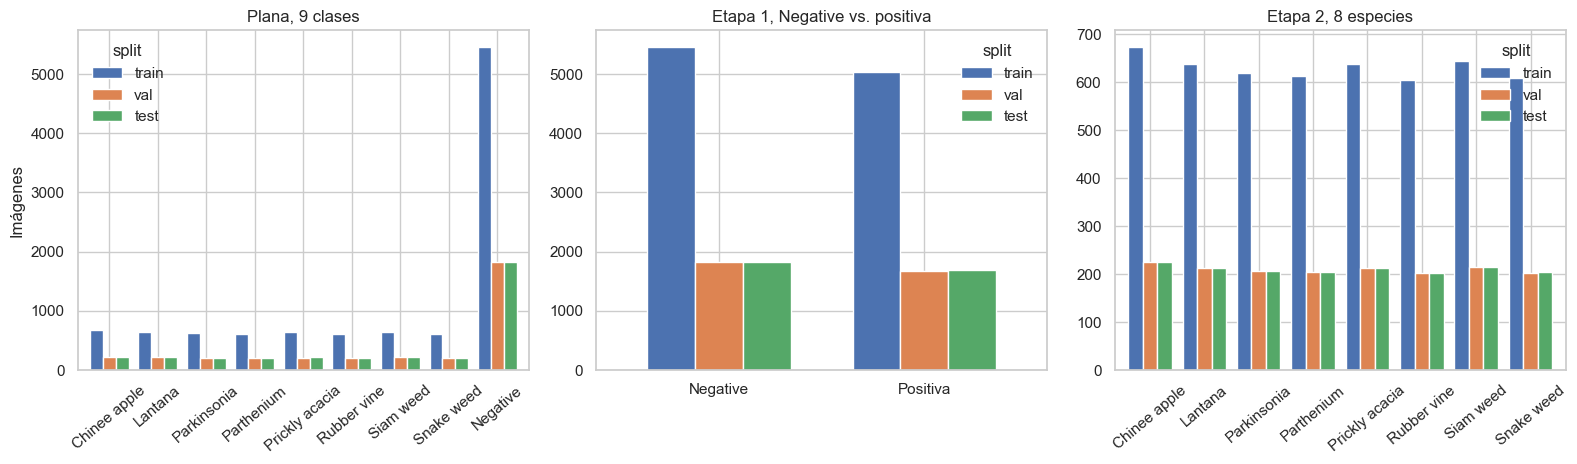

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

PESOS = pesos_del_fold(manifiesto, FOLD_TRABAJO)
exigir_politica_de_pesos(PESOS, label_negative=8)

for tarea, mapa in PESOS.items():
    serie = pd.Series(mapa, name="peso").sort_index()
    serie.index.name = "clase"
    print(f"{tarea} | ponderar en el entrenamiento: {USAR_PONDERACION[tarea]}")
    display(serie.round(3).to_frame())


def graficar_vistas(tabla_manifiesto: pd.DataFrame, fold: int, ruta: Path):
    """Barras de las tres formulaciones en train, val y test."""
    columna = f"split_{fold}"
    fig, ejes = plt.subplots(1, 3, figsize=(16, 4.8))

    plana = (tabla_manifiesto.groupby(["Species", columna]).size()
             .unstack(columna)
             .reindex(index=ORDEN_ESPECIES, columns=SUBCONJUNTOS))
    plana.plot(kind="bar", ax=ejes[0], rot=40, width=0.8)
    ejes[0].set_title("Plana, 9 clases")
    ejes[0].set_xlabel("")
    ejes[0].set_ylabel("Imágenes")

    etapa1 = (tabla_manifiesto.groupby(["y_etapa1", columna]).size()
              .unstack(columna)
              .rename(index={0: "Negative", 1: "Positiva"})
              .reindex(columns=SUBCONJUNTOS))
    etapa1.plot(kind="bar", ax=ejes[1], rot=0, width=0.7)
    ejes[1].set_title("Etapa 1, Negative vs. positiva")
    ejes[1].set_xlabel("")

    positivas = tabla_manifiesto.loc[tabla_manifiesto["y_etapa1"] == 1]
    etapa2 = (positivas.groupby(["Species", columna]).size()
              .unstack(columna)
              .reindex(index=ORDEN_ESPECIES[:-1], columns=SUBCONJUNTOS))
    etapa2.plot(kind="bar", ax=ejes[2], rot=40, width=0.8)
    ejes[2].set_title("Etapa 2, 8 especies")
    ejes[2].set_xlabel("")

    for eje in ejes:
        eje.legend(title="split", frameon=False)
    fig.tight_layout()
    fig.savefig(ruta, dpi=120, bbox_inches="tight")
    return fig


RUTA_VISTAS = DIR_FIGURAS / f"02_vistas_fold{FOLD_TRABAJO}.png"
graficar_vistas(manifiesto, FOLD_TRABAJO, RUTA_VISTAS)
print(f"Figura: {RUTA_VISTAS}")


**Observación.** En la tarea plana Negative pesa menos de 1 y cada especie pesa más de 1: es el único sitio donde la ponderación compensa el ρ de 9,02. En las dos etapas los pesos caen entre 0,9 y 1,2, así que entrenarlas con ponderación no cambia el problema y no se hace. El umbral con el que la etapa 1 manda una imagen a la etapa 2 no se fija aquí: un falso positivo sobre vegetación nativa y un falso negativo no cuestan lo mismo, y ese corte se elige en validación.


## 5. Registro de backbones

Todas las redes ven el mismo fold, el mismo aumento y, cuando hay transfer learning, pesos de ImageNet. Lo que cambia es la función de preprocesado. El lado de la comparación queda en 224 aunque Inception-v3 sea nativa a 299 y EfficientNet-B4 a 380.

Ese rango no se asume: se mide con la Keras de esta sesión. En Keras 3, `preprocess_input` de EfficientNet es la identidad y los píxeles siguen en 0–255, porque la normalización ya va dentro del modelo. Escalarlos a [−1, 1] antes de entrar los transformaría dos veces.

La primera ola de entrenamiento es la CNN desde cero, ResNet-50, Inception-v3 y EfficientNet-B0. EfficientNet-B4 es la arquitectura del 99,26 % de Duong et al. (2024), pero ese número también cambia la partición, el aumento y el preentrenamiento (Adversarial Propagation, Noisy Student). Esas dos últimas variantes no entran. MobileNetV2 queda registrada por el requisito de inferencia de la Entrega 1, por debajo de 100 ms. Las seis tienen que pasar el lote de humo; entrenar B4 y MobileNetV2 depende de la GPU y no se decide en este cuaderno.


In [5]:
import json

import tensorflow as tf

tf.random.set_seed(SEED)
try:
    import keras
    version_keras = keras.__version__
except Exception:
    version_keras = "incluida en tensorflow"
print(f"tensorflow {tf.__version__} | keras {version_keras}")

REGISTRO = {
    "scratch": {
        "papel": "Línea interna de la Entrega 1, sin pesos de ImageNet.",
        "lado": LADO_COMPARACION,
        "nativo": LADO_COMPARACION,
        "preprocess": "(x - media_train) / std_train",
        "modo_rango": "zscore",
        "pesos": None,
        "entrenar_en_la_primera_ola": True,
    },
    "ResNet50": {
        "papel": "Baseline de Olsen et al. (2019), 95,7 % de accuracy.",
        "lado": LADO_COMPARACION,
        "nativo": 224,
        "preprocess": "tensorflow.keras.applications.resnet.preprocess_input",
        "modo_rango": "caffe",
        "pesos": "imagenet",
        "entrenar_en_la_primera_ola": True,
    },
    "InceptionV3": {
        "papel": "Segundo baseline de Olsen et al. (2019), 95,1 % de accuracy.",
        "lado": LADO_COMPARACION,
        "nativo": 299,
        "preprocess": "tensorflow.keras.applications.inception_v3.preprocess_input",
        "modo_rango": "tf",
        "pesos": "imagenet",
        "entrenar_en_la_primera_ola": True,
    },
    "EfficientNetB0": {
        "papel": "Familia EfficientNet de Duong et al. (2024), tamaño que cabe en Colab.",
        "lado": LADO_COMPARACION,
        "nativo": 224,
        "preprocess": "tensorflow.keras.applications.efficientnet.preprocess_input",
        "modo_rango": "tf",
        "pesos": "imagenet",
        "entrenar_en_la_primera_ola": True,
    },
    "EfficientNetB4": {
        "papel": "Arquitectura del 99,26 % de Duong et al. (2024). Otro protocolo: no se reproduce esa cifra.",
        "lado": LADO_COMPARACION,
        "nativo": 380,
        "preprocess": "tensorflow.keras.applications.efficientnet.preprocess_input",
        "modo_rango": "tf",
        "pesos": "imagenet",
        "entrenar_en_la_primera_ola": False,
    },
    "MobileNetV2": {
        "papel": "Candidata ligera para el límite de 100 ms de la Entrega 1.",
        "lado": LADO_COMPARACION,
        "nativo": 224,
        "preprocess": "tensorflow.keras.applications.mobilenet_v2.preprocess_input",
        "modo_rango": "tf",
        "pesos": "imagenet",
        "entrenar_en_la_primera_ola": False,
    },
}

from tensorflow.keras.applications.efficientnet import preprocess_input as preprocess_efficientnet
from tensorflow.keras.applications.inception_v3 import preprocess_input as preprocess_inception
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as preprocess_mobilenet
from tensorflow.keras.applications.resnet import preprocess_input as preprocess_resnet

PREPROCESS = {
    "ResNet50": preprocess_resnet,
    "InceptionV3": preprocess_inception,
    "EfficientNetB0": preprocess_efficientnet,
    "EfficientNetB4": preprocess_efficientnet,
    "MobileNetV2": preprocess_mobilenet,
}
exigir(set(PREPROCESS) == set(REGISTRO) - {"scratch"}, "El registro y las funciones de preprocesado no coinciden.")
exigir(
    all(entrada["lado"] == LADO_COMPARACION for entrada in REGISTRO.values()),
    "La comparación controlada exige el mismo lado en todas las redes.",
)


def clasificar_preprocess(funcion) -> str:
    """Mide qué hace preprocess_input con píxeles en [0, 255].

    En Keras 3 el de EfficientNet es la identidad: la normalización va dentro
    de la red. Forzar [-1, 1] a mano la aplicaría dos veces.
    """
    negro = tf.zeros((1, 8, 8, 3), tf.float32)
    blanco = tf.ones((1, 8, 8, 3), tf.float32) * 255.0
    minimo = float(tf.reduce_min(funcion(negro)))
    maximo = float(tf.reduce_max(funcion(blanco)))
    if abs(minimo) < 1.0 and abs(maximo - 255.0) < 1.0:
        return "en_el_modelo"
    if abs(minimo + 1.0) < 0.05 and abs(maximo - 1.0) < 0.05:
        return "tf"
    if minimo < -50.0 and maximo > 50.0:
        return "caffe"
    raise ValueError(
        f"preprocess_input devolvió un rango no reconocido (min {minimo:.2f}, max {maximo:.2f})."
    )


for clave, funcion in PREPROCESS.items():
    REGISTRO[clave]["modo_rango"] = clasificar_preprocess(funcion)

print("Rango medido de preprocess_input en esta versión de Keras:")
for clave in PREPROCESS:
    print(f"  {clave:16} {REGISTRO[clave]['modo_rango']}")

RUTA_REGISTRO = DIR_DATOS / "registro_backbones.json"
RUTA_REGISTRO.write_text(json.dumps({
    "comparacion_controlada_lado": LADO_COMPARACION,
    "nota": (
        "El lado 224 aísla el backbone de la resolución. "
        "InceptionV3 nativa es 299 y EfficientNetB4 nativa es 380; "
        "subirlas a ese lado es otra corrida y no la comparación principal. "
        "No se usan AdvProp ni Noisy Student."
    ),
    "backbones": REGISTRO,
}, indent=2, ensure_ascii=False), encoding="utf-8")

display(pd.DataFrame(REGISTRO).T[["papel", "lado", "nativo", "modo_rango", "entrenar_en_la_primera_ola"]])
print(f"Registro escrito en {RUTA_REGISTRO}")


tensorflow 2.21.0 | keras 3.15.1
Rango medido de preprocess_input en esta versión de Keras:
  ResNet50         caffe
  InceptionV3      tf
  EfficientNetB0   en_el_modelo
  EfficientNetB4   en_el_modelo
  MobileNetV2      tf


,papel,lado,nativo,modo_rango,entrenar_en_la_primera_ola
scratch,"Línea interna de la Entrega 1, sin pesos de Im...",224,224,zscore,True
ResNet50,"Baseline de Olsen et al. (2019), 95,7 % de acc...",224,224,caffe,True
InceptionV3,"Segundo baseline de Olsen et al. (2019), 95,1 ...",224,299,tf,True
EfficientNetB0,"Familia EfficientNet de Duong et al. (2024), t...",224,224,en_el_modelo,True
EfficientNetB4,"Arquitectura del 99,26 % de Duong et al. (2024...",224,380,en_el_modelo,False
MobileNetV2,Candidata ligera para el límite de 100 ms de l...,224,224,tf,False


Registro escrito en datos\registro_backbones.json


## 6. Media y desviación de la CNN desde cero

La CNN desde cero no usa `preprocess_input`. Hay dos poblaciones, las dos estimadas solo con el train del fold de trabajo, después del mismo resize que verá el modelo y sin aumento:

- `plana_etapa1`: todas las imágenes de train. La etapa 1 clasifica otra etiqueta sobre los mismos píxeles.
- `etapa2`: solo las positivas de train. Esa red no ve Negative, y la media de Negative no entra en su normalización.

Val y test reutilizan esas constantes. No se recalculan en cada época ni sobre imágenes aumentadas. El resize es bilineal con antialias, idéntico al del pipeline.


In [6]:
import time


def leer_redimensionada(ruta: str, lado: int) -> tf.Tensor:
    """Lee un JPG y lo deja en float32 [0, 255] del lado indicado.

    No divide entre 255. Las funciones preprocess_input de Keras esperan
    esa escala y ellas mismas hacen la conversión.
    """
    imagen = tf.io.decode_jpeg(tf.io.read_file(ruta), channels=3)
    imagen = tf.image.resize(imagen, [lado, lado], method="bilinear", antialias=True)
    return tf.cast(imagen, tf.float32)


def estadisticos_canal(nombres: list[str], rutas: list[str], lado: int) -> dict:
    """Media y desviación por canal, en un pase, sin cargar el corpus en memoria.

    Args:
        nombres: Filenames, en el mismo orden que `rutas`.
        rutas: Rutas legibles por TensorFlow.
        lado: Lado del resize, en píxeles.

    Returns:
        Media, desviación, conteo y la firma de los filenames.

    Raises:
        RuntimeError: Si no se leyeron todas las rutas o un canal sale con
            desviación nula.
    """
    if len(nombres) != len(rutas) or not rutas:
        raise ValueError("La lista de imágenes para la media está vacía o desalineada.")
    faltantes = [ruta for ruta in rutas if not Path(ruta).is_file()]
    if faltantes:
        raise FileNotFoundError(f"Faltan {len(faltantes)} imágenes. Ejemplo: {faltantes[0]}")

    def leer(ruta, lado_fijo=lado):
        return leer_redimensionada(ruta, lado_fijo)

    dataset = tf.data.Dataset.from_tensor_slices(rutas)
    dataset = dataset.map(
        leer,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=True,
    ).batch(64).prefetch(2)

    suma = np.zeros(3, dtype=np.float64)
    suma_cuadrados = np.zeros(3, dtype=np.float64)
    n_imagenes = 0
    for lote in dataset:
        arreglo = lote.numpy().astype(np.float64)
        suma += arreglo.sum(axis=(0, 1, 2))
        suma_cuadrados += np.square(arreglo).sum(axis=(0, 1, 2))
        n_imagenes += int(arreglo.shape[0])

    if n_imagenes != len(rutas):
        raise RuntimeError(f"Se leyeron {n_imagenes} imágenes de {len(rutas)}.")
    pixeles = n_imagenes * lado * lado
    media = suma / pixeles
    varianza = suma_cuadrados / pixeles - np.square(media)
    if np.any(varianza <= 1e-8):
        raise RuntimeError("Un canal salió con desviación nula.")
    desviacion = np.sqrt(varianza)
    return {
        "media": [round(float(valor), 6) for valor in media],
        "std": [round(float(valor), 6) for valor in desviacion],
        "n_imagenes": n_imagenes,
        "lado": lado,
        "firma_nombres": firma_nombres(nombres),
    }


def rutas_de(tabla_manifiesto: pd.DataFrame, dir_imagenes: Path, fold: int,
             split: str, solo_positivas: bool) -> tuple[list[str], list[str]]:
    """Filenames y rutas de un split. Si solo_positivas, aplica el filtro de la etapa 2."""
    filas = tabla_manifiesto.loc[tabla_manifiesto[f"split_{fold}"] == split]
    if solo_positivas:
        filas = filas.loc[filas["y_etapa1"].astype(int) == 1]
    nombres = filas["Filename"].tolist()
    return nombres, [(dir_imagenes / nombre).as_posix() for nombre in nombres]


nombres_train, rutas_train = rutas_de(manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "train", False)
nombres_etapa2, rutas_etapa2 = rutas_de(manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "train", True)
nombres_test, _ = rutas_de(manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "test", False)
exigir(set(nombres_train).isdisjoint(nombres_test), "Train y test comparten filenames.")
exigir(set(nombres_etapa2) <= set(nombres_train), "La media de la etapa 2 no sale solo de train.")

print(f"Estimando media y desviación sobre {len(rutas_train)} imágenes de train...")
inicio = time.perf_counter()
estad_train = estadisticos_canal(nombres_train, rutas_train, LADO_COMPARACION)
estad_etapa2 = estadisticos_canal(nombres_etapa2, rutas_etapa2, LADO_COMPARACION)
print(f"Listo en {time.perf_counter() - inicio:.0f} s")

exigir(estad_train["n_imagenes"] == len(nombres_train), "La media plana no cubre el train.")
exigir(estad_etapa2["n_imagenes"] == len(nombres_etapa2), "La media de la etapa 2 no cubre sus positivas.")
exigir(estad_train["firma_nombres"] == firma_nombres(nombres_train), "La firma del train no cierra.")
exigir(all(desviacion > 1 for desviacion in estad_train["std"]), "La desviación no está en escala 0–255.")

NORMATIVAS = {
    "fold": FOLD_TRABAJO,
    "lado": LADO_COMPARACION,
    "interpolacion": "bilinear",
    "antialias": True,
    "plana_etapa1": estad_train,
    "etapa2": estad_etapa2,
    "pesos": {tarea: {str(clase): peso for clase, peso in mapa.items()} for tarea, mapa in PESOS.items()},
    "usar_ponderacion": USAR_PONDERACION,
}
RUTA_NORM = DIR_DATOS / f"norm_scratch_fold{FOLD_TRABAJO}.json"
RUTA_NORM.write_text(json.dumps(NORMATIVAS, indent=2), encoding="utf-8")

resumen_norm = pd.DataFrame({
    "plana_etapa1": estad_train["media"] + estad_train["std"],
    "etapa2": estad_etapa2["media"] + estad_etapa2["std"],
}, index=["media_R", "media_G", "media_B", "std_R", "std_G", "std_B"])
display(resumen_norm.round(2))
print(f"Imágenes plana/etapa1: {estad_train['n_imagenes']} | etapa 2: {estad_etapa2['n_imagenes']}")
print(f"Normalización escrita en {RUTA_NORM}")


Estimando media y desviación sobre 10501 imágenes de train...
Listo en 63 s


,plana_etapa1,etapa2
media_R,95.41,89.48
media_G,99.32,95.65
media_B,95.56,90.65
std_R,52.37,53.32
std_G,51.89,54.27
std_B,51.26,52.78


Imágenes plana/etapa1: 10501 | etapa 2: 5038
Normalización escrita en datos\norm_scratch_fold0.json


**Observación.** Las dos medias salen de poblaciones distintas a propósito. La etapa 2 no hereda el color de Negative. Los valores están en la escala 0–255 del JPG, no en 0–1: esa es la escala que después se estandariza con `(x - media) / std`. Esas constantes no se tocan en el cuaderno de modelado.


## 7. Aumento de datos

Solo en train, y siempre antes de normalizar. El orden es el de la política: giro, escala, brillo, desplazamiento por canal y volteo horizontal. Al final se recorta a [0, 255].

Olsen et al. (2019) también aumentan la validación en cada época, giran y escalan con un rango más agresivo (`escala` hasta 0,5) y aplican un cambio de perspectiva. Aquí la validación y el test quedan fijos: si la validación se mueve, el early stopping no tiene una cifra estable. La escala inicial es [0,85, 1,15] para no sacar la planta del cuadro; si la grilla de train muestra que desaparece, se editan `ESCALA_MIN` y `ESCALA_MAX` y se vuelve a correr esta sección. No se ajustan mirando accuracy de validación ni de test.

No hay volteo vertical. Las fotos tienen eje de cámara (suelo, sombras, horizonte), como se vio en el cuaderno 01. El brillo aditivo de ±25 y la escala de intensidad [0,75, 1,25], más el desplazamiento por canal de ±25, son los de Olsen y responden al atajo de brillo e instrumento.


Figura: figuras\02_aumentos_fold0.png


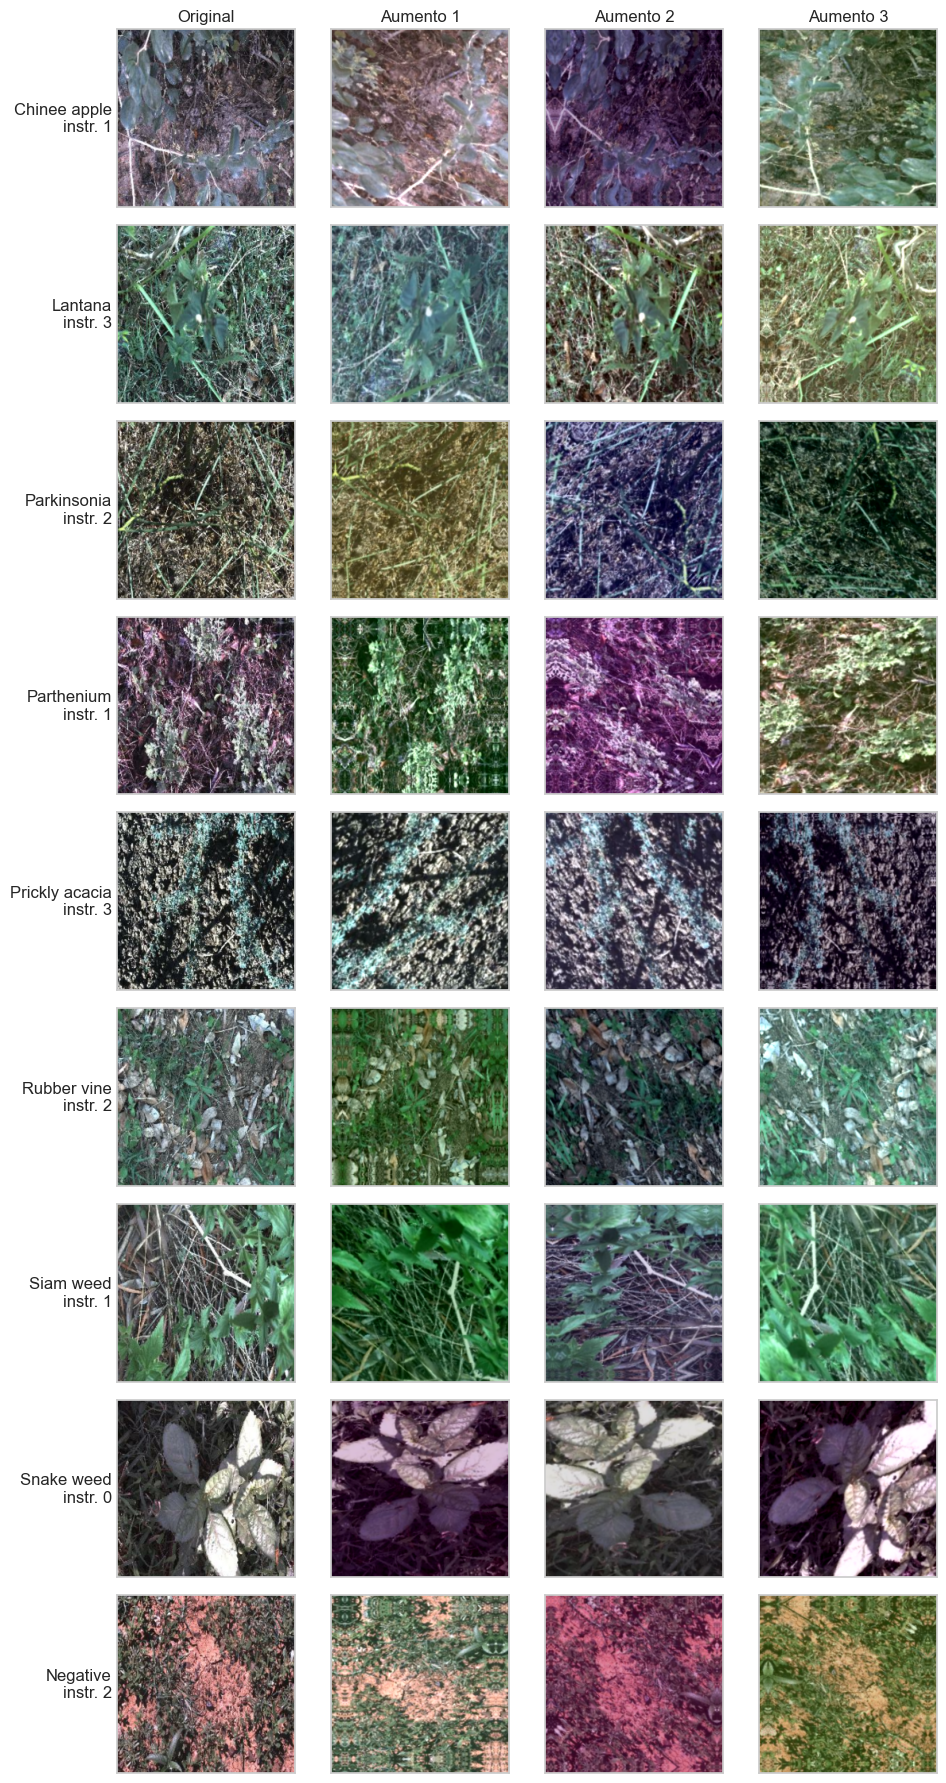

In [7]:
def matriz_rotacion(angulo, alto, ancho) -> tf.Tensor:
    """Matriz proyectiva 1×8, la misma fórmula que Keras RandomRotation.

    Mapea el píxel de salida al píxel de entrada. Un ángulo 0 deja la imagen quieta.
    """
    angulo = tf.reshape(tf.cast(angulo, tf.float32), [1])
    alto = tf.cast(alto, tf.float32)
    ancho = tf.cast(ancho, tf.float32)
    coseno = tf.cos(angulo)
    seno = tf.sin(angulo)
    desplazamiento_x = ((ancho - 1) - (coseno * (ancho - 1) - seno * (alto - 1))) / 2.0
    desplazamiento_y = ((alto - 1) - (seno * (ancho - 1) + coseno * (alto - 1))) / 2.0
    ceros = tf.zeros([1, 2], dtype=tf.float32)
    return tf.concat([
        coseno[:, None], -seno[:, None], desplazamiento_x[:, None],
        seno[:, None], coseno[:, None], desplazamiento_y[:, None],
        ceros,
    ], axis=1)


def rotar_imagen(imagen: tf.Tensor, angulo) -> tf.Tensor:
    """Gira una imagen HWC. El borde se rellena por reflejo, no con negro."""
    imagen_4d = imagen[tf.newaxis, ...]
    alto = tf.shape(imagen_4d)[1]
    ancho = tf.shape(imagen_4d)[2]
    salida = tf.raw_ops.ImageProjectiveTransformV3(
        images=imagen_4d,
        transforms=matriz_rotacion(angulo, alto, ancho),
        output_shape=tf.cast(tf.stack([alto, ancho]), tf.int32),
        fill_value=tf.constant(0.0, tf.float32),
        interpolation="BILINEAR",
        fill_mode="REFLECT",
    )
    return salida[0]


def ajustar_al_tamano(imagen: tf.Tensor, alto, ancho) -> tf.Tensor:
    """Rellena por reflejo o recorta al centro hasta (alto, ancho)."""
    falta_alto = tf.maximum(alto - tf.shape(imagen)[0], 0)
    falta_ancho = tf.maximum(ancho - tf.shape(imagen)[1], 0)
    imagen = tf.pad(
        imagen,
        [[falta_alto // 2, falta_alto - falta_alto // 2],
         [falta_ancho // 2, falta_ancho - falta_ancho // 2],
         [0, 0]],
        mode="REFLECT",
    )
    inicio_alto = (tf.shape(imagen)[0] - alto) // 2
    inicio_ancho = (tf.shape(imagen)[1] - ancho) // 2
    return imagen[inicio_alto:inicio_alto + alto, inicio_ancho:inicio_ancho + ancho, :]


def escalar_y_recortar(imagen: tf.Tensor, factor) -> tf.Tensor:
    """Escala y devuelve al tamaño original. factor > 1 acerca; factor < 1 aleja."""
    alto = tf.shape(imagen)[0]
    ancho = tf.shape(imagen)[1]
    nuevo_alto = tf.maximum(tf.cast(tf.round(tf.cast(alto, tf.float32) * factor), tf.int32), 1)
    nuevo_ancho = tf.maximum(tf.cast(tf.round(tf.cast(ancho, tf.float32) * factor), tf.int32), 1)
    escalada = tf.image.resize(imagen, [nuevo_alto, nuevo_ancho], method="bilinear")
    return ajustar_al_tamano(escalada, alto, ancho)


def aumentar_imagen(imagen: tf.Tensor) -> tf.Tensor:
    """Aplica la política de aumento y recorta el resultado a [0, 255].

    Pensada solo para train. Dos llamadas sobre la misma imagen deben diferir.
    """
    angulo = tf.random.uniform([], -GIRO_MAXIMO_RAD, GIRO_MAXIMO_RAD)
    imagen = rotar_imagen(imagen, angulo)
    factor = tf.random.uniform([], ESCALA_MIN, ESCALA_MAX)
    imagen = escalar_y_recortar(imagen, factor)
    escala = tf.random.uniform([], BRILLO_ESCALA_MIN, BRILLO_ESCALA_MAX)
    aditivo = tf.random.uniform([], -BRILLO_ADITIVO, BRILLO_ADITIVO)
    canales = tf.random.uniform([1, 1, 3], -DESPLAZAMIENTO_CANAL, DESPLAZAMIENTO_CANAL)
    imagen = imagen * escala + aditivo + canales
    imagen = tf.image.random_flip_left_right(imagen)
    return tf.clip_by_value(imagen, 0.0, 255.0)


def brillo_medio(imagen: tf.Tensor) -> float:
    """Media de la luminancia, con los pesos usados en el cuaderno 01."""
    pesos = tf.constant([0.299, 0.587, 0.114], dtype=tf.float32)
    return float(tf.reduce_mean(tf.tensordot(imagen, pesos, axes=[[-1], [0]])))


rampa = tf.reshape(tf.linspace(0.0, 255.0, 32 * 32), [32, 32, 1])
rampa = tf.tile(rampa, [1, 1, 3])
giro_nulo = rotar_imagen(rampa, 0.0)
exigir(float(tf.reduce_max(tf.abs(giro_nulo - rampa))) < 1.0, "Un giro de 0° movió la imagen.")
giro_real = rotar_imagen(rampa, 0.7)
exigir(float(tf.reduce_max(tf.abs(giro_real - rampa))) > 10.0, "El giro no cambió la imagen.")
escala_nula = escalar_y_recortar(rampa, 1.0)
exigir(float(tf.reduce_max(tf.abs(escala_nula - rampa))) < 1.0, "Una escala de 1 cambió la imagen.")


def muestras_de_train(tabla_manifiesto: pd.DataFrame, fold: int, n: int, semilla: int) -> pd.DataFrame:
    """Hasta n imágenes de train por especie. No toca val ni test."""
    train = tabla_manifiesto.loc[tabla_manifiesto[f"split_{fold}"] == "train"]
    return pd.concat([
        grupo.sample(min(n, len(grupo)), random_state=semilla)
        for _, grupo in train.groupby("Species")
    ])


def un_ejemplo_por_clase(tabla_manifiesto: pd.DataFrame, fold: int, semilla: int) -> pd.DataFrame:
    """Una imagen de train por especie, en el orden de Olsen."""
    ejemplos = muestras_de_train(tabla_manifiesto, fold, 1, semilla)
    return ejemplos.set_index("Species").loc[ORDEN_ESPECIES]


ejemplos = un_ejemplo_por_clase(manifiesto, FOLD_TRABAJO, SEED)
columnas_grilla = 4
fig, ejes = plt.subplots(len(ORDEN_ESPECIES), columnas_grilla, figsize=(10, 18))
for i, especie in enumerate(ORDEN_ESPECIES):
    fila = ejemplos.loc[especie]
    original = leer_redimensionada((DIR_IMAGENES / fila["Filename"]).as_posix(), LADO_COMPARACION)
    versiones = [original] + [aumentar_imagen(original) for _ in range(3)]
    for j, version in enumerate(versiones):
        ejes[i, j].imshow(tf.cast(tf.round(version), tf.uint8).numpy())
        ejes[i, j].set_xticks([])
        ejes[i, j].set_yticks([])
        if i == 0:
            ejes[i, j].set_title("Original" if j == 0 else f"Aumento {j}")
    ejes[i, 0].set_ylabel(f"{especie}\ninstr. {int(fila['instrumento'])}", rotation=0, ha="right", va="center")

fig.tight_layout()
RUTA_AUMENTOS = DIR_FIGURAS / f"02_aumentos_fold{FOLD_TRABAJO}.png"
fig.savefig(RUTA_AUMENTOS, dpi=100, bbox_inches="tight")
print(f"Figura: {RUTA_AUMENTOS}")


momento,antes,despues,delta
Species,,,
Chinee apple,89.7,92.0,2.3
Lantana,97.5,98.9,1.4
Parkinsonia,91.2,88.9,-2.3
Parthenium,86.8,85.2,-1.6
Prickly acacia,86.0,86.1,0.1
Rubber vine,98.1,99.1,0.9
Siam weed,107.7,111.4,3.6
Snake weed,85.3,89.5,4.2
Negative,102.3,101.7,-0.6


Figura: figuras\02_brillo_fold0.png


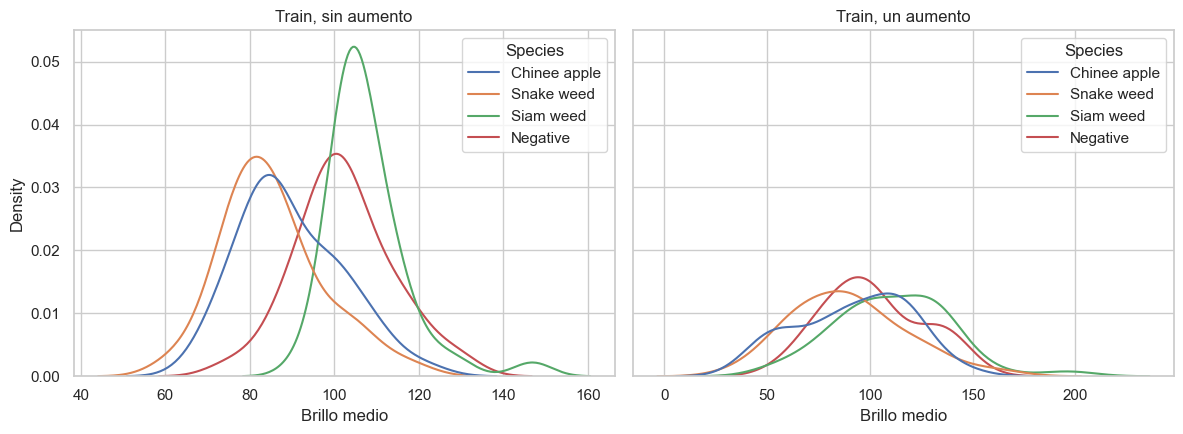

In [8]:
muestra = muestras_de_train(manifiesto, FOLD_TRABAJO, MUESTRA_BRILLO, SEED)
registros_brillo = []
for fila in muestra.itertuples(index=False):
    original = leer_redimensionada((DIR_IMAGENES / fila.Filename).as_posix(), LADO_COMPARACION)
    aumentada = aumentar_imagen(original)
    registros_brillo.append({"Species": fila.Species, "momento": "antes", "brillo": brillo_medio(original)})
    registros_brillo.append({"Species": fila.Species, "momento": "despues", "brillo": brillo_medio(aumentada)})

brillos = pd.DataFrame(registros_brillo)
resumen_brillo = brillos.groupby(["Species", "momento"])["brillo"].mean().unstack()
resumen_brillo = resumen_brillo.reindex(ORDEN_ESPECIES)
resumen_brillo["delta"] = resumen_brillo["despues"] - resumen_brillo["antes"]
display(resumen_brillo.round(1))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for eje, momento, titulo in zip(ejes, ["antes", "despues"], ["Train, sin aumento", "Train, un aumento"]):
    sns.kdeplot(
        data=brillos.loc[brillos["Species"].isin(CLASES_BRILLO) & (brillos["momento"] == momento)],
        x="brillo", hue="Species", hue_order=CLASES_BRILLO, common_norm=False, ax=eje,
    )
    eje.set_title(titulo)
    eje.set_xlabel("Brillo medio")
fig.tight_layout()
RUTA_BRILLO = DIR_FIGURAS / f"02_brillo_fold{FOLD_TRABAJO}.png"
fig.savefig(RUTA_BRILLO, dpi=120, bbox_inches="tight")
print(f"Figura: {RUTA_BRILLO}")


**Observación.** La grilla y el histograma usan solo train. La escala queda congelada en [0,85, 1,15]: es la decisión previa al test, no un resultado que se vaya a retocar con la métrica. El histograma muestra si el aumento de brillo acerca las clases que el cuaderno 01 separó por luminancia (Chinee apple y Snake weed oscuras, Siam weed brillante). Esa tabla es de una muestra y de un sorteo del aumento; no se usa para elegir el modelo.

Olsen aumenta la validación y Duong et al. (2024) no publican si el aumento ocurrió antes o después de partir. Aquí el aumento es posterior al split y exclusivo del train.


## 8. Pipeline `tf.data`

Un solo constructor. El modelado lo llama con la etapa y el modo; no vuelve a armar el split.

- `entrenar=True` solo es válido en train, y en la etapa 2 solo con `modo='aislado'`.
- Val y test no se barajan y la tupla es `(imagen, etiqueta, filename)`. El filename es el del manifiesto, para cruzar errores con el instrumento.
- No se cachea ningún split. Cachear el train después del aumento lo congelaría, y cachear la validación en RAM compite con la red.
- La normalización es la última operación. Nunca va un `/255` delante de `preprocess_input`.
- Para la CNN desde cero, la etapa 2 usa la media de las positivas aunque el modo sea end-to-end. Ese lote no se mete en la red de la etapa 1: para la etapa 1 se construye otro dataset con `etapa='etapa1'`, y el orden de los filenames coincide.


In [9]:
def grupo_normalizacion(etapa: str) -> str:
    """Población de media y desviación que corresponde a la cabeza."""
    return "etapa2" if etapa == "etapa2" else "plana_etapa1"


def construir_dataset(tabla_manifiesto: pd.DataFrame, dir_imagenes: Path, fold: int,
                      split: str, etapa: str, modo: str, clave: str, entrenar: bool,
                      estadisticos: dict, batch_size: int = BATCH_DEFAULT) -> tf.data.Dataset:
    """Dataset de una vista, con aumento solo si se está entrenando el train.

    Args:
        tabla_manifiesto: Manifiesto del cuaderno.
        dir_imagenes: Carpeta de JPG.
        fold: Fold oficial.
        split: 'train', 'val' o 'test'.
        etapa: 'plana', 'etapa1' o 'etapa2'.
        modo: 'aislado' o 'e2e'.
        clave: Clave del registro de backbones.
        entrenar: Si es verdad, aplica aumento y baraja. Solo en train.
        estadisticos: Contenido de norm_scratch_fold{k}.json.
        batch_size: Tamaño de lote. No es una decisión de modelado cerrada aquí.

    Returns:
        Dataset de tuplas (imagen float32, etiqueta int32, filename).

    Raises:
        ValueError: Si se pide entrenar sobre val, test o sobre el end-to-end
            de la etapa 2.
        KeyError: Si el backbone no está en el registro.
    """
    if clave not in REGISTRO:
        raise KeyError(f"Backbone desconocido: {clave}")
    if entrenar and split != "train":
        raise ValueError("El aumento solo está definido para el split de train.")
    if entrenar and etapa == "etapa2" and modo == "e2e":
        raise ValueError(
            "La etapa 2 no se entrena con el split completo. "
            "Use modo='aislado' para entrenar y modo='e2e' solo para evaluar."
        )

    filas = seleccionar_filas(tabla_manifiesto, fold, split, etapa, modo)
    if filas.empty:
        raise ValueError(f"La vista {etapa}/{modo}/{split} quedó vacía.")

    lado = int(REGISTRO[clave]["lado"])
    rutas = [(dir_imagenes / nombre).as_posix() for nombre in filas["Filename"]]
    etiquetas = filas["y"].astype(int).tolist()
    nombres = filas["Filename"].tolist()

    if clave == "scratch":
        grupo = estadisticos[grupo_normalizacion(etapa)]
        media = tf.constant(grupo["media"], dtype=tf.float32)
        desviacion = tf.constant(grupo["std"], dtype=tf.float32)

        def normalizar(imagen):
            return (imagen - media) / desviacion
    else:
        funcion = PREPROCESS[clave]

        def normalizar(imagen):
            # preprocess_input espera 0–255. No anteponer x/255.
            return funcion(imagen)

    def cargar(ruta, etiqueta, nombre):
        imagen = leer_redimensionada(ruta, lado)
        if entrenar:
            imagen = aumentar_imagen(imagen)
        imagen = normalizar(imagen)
        imagen.set_shape([lado, lado, 3])
        return imagen, tf.cast(etiqueta, tf.int32), nombre

    dataset = tf.data.Dataset.from_tensor_slices((rutas, etiquetas, nombres))
    if entrenar:
        dataset = dataset.shuffle(len(filas), seed=SEED, reshuffle_each_iteration=True)
    dataset = dataset.map(
        cargar,
        num_parallel_calls=tf.data.AUTOTUNE,
        deterministic=not entrenar,
    )
    return dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)


def textos(tensor) -> list[str]:
    """Decodifica un tensor de strings de TensorFlow."""
    return [valor.decode("utf-8") for valor in tensor.numpy()]


# Val y test no se mueven. Train, sí.
ds_val = construir_dataset(
    manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "val", "plana", "e2e",
    "scratch", False, NORMATIVAS, batch_size=1,
)
lectura_a = next(iter(ds_val))
lectura_b = next(iter(ds_val))
exigir(bool(tf.reduce_all(lectura_a[0] == lectura_b[0])), "La validación cambió entre dos lecturas.")
exigir(bool(tf.reduce_all(lectura_a[1] == lectura_b[1])), "La etiqueta de validación cambió entre dos lecturas.")

original_train = leer_redimensionada(
    (DIR_IMAGENES / nombres_train[0]).as_posix(), LADO_COMPARACION,
)
aumento_a = aumentar_imagen(original_train)
aumento_b = aumentar_imagen(original_train)
exigir(
    float(tf.reduce_max(tf.abs(aumento_a - aumento_b))) > 1.0,
    "Dos aumentos seguidos de la misma imagen de train salieron iguales.",
)
print("Validación estable y aumento de train distinto en dos llamadas.")


Validación estable y aumento de train distinto en dos llamadas.


## 9. Lote de humo

Una pasada por las seis claves, sin crear la red y sin descargar los pesos de ImageNet. Se comprueba la forma, que la validación sale en el orden del manifiesto, y el rango:

- ResNet-50, modo caffe: si los píxeles hubieran llegado en [0, 1], toda la imagen quedaría negativa después de restar las medias (~100). Con la escala 0–255 el máximo es positivo.
- Modo tf: el lote queda en [−1, 1]. Lo cumple Inception-v3, y MobileNetV2 si su función todavía escala.
- Modo `en_el_modelo`: el lote sigue en 0–255. Es EfficientNet en Keras 3, porque la red normaliza al entrar.
- CNN desde cero: la media del lote queda cerca de 0. No es la misma transformación que `preprocess_input`.


In [10]:
# revision-humo: efficientnet queda en 0-255
def medir_modo_preprocess(clave: str) -> str:
    """Mide preprocess_input en esta celda. No reutiliza un modo viejo en memoria."""
    if clave == "scratch":
        return "zscore"
    funcion = PREPROCESS[clave]
    negro = tf.zeros((1, 8, 8, 3), tf.float32)
    blanco = tf.ones((1, 8, 8, 3), tf.float32) * 255.0
    minimo = float(tf.reduce_min(funcion(negro)))
    maximo = float(tf.reduce_max(funcion(blanco)))
    if abs(minimo) < 1.0 and abs(maximo - 255.0) < 1.0:
        modo = "en_el_modelo"
    elif abs(minimo + 1.0) < 0.05 and abs(maximo - 1.0) < 0.05:
        modo = "tf"
    elif minimo < -50.0 and maximo > 50.0:
        modo = "caffe"
    else:
        raise ValueError(
            f"{clave}: preprocess_input devolvió min {minimo:.2f}, max {maximo:.2f}."
        )
    REGISTRO[clave]["modo_rango"] = modo
    return modo


def comprobar_rango(clave: str, lote: tf.Tensor) -> None:
    """Rechaza un /255 de más y una normalización cruzada entre backbones."""
    minimo = float(tf.reduce_min(lote))
    maximo = float(tf.reduce_max(lote))
    modo = medir_modo_preprocess(clave)
    if modo == "caffe":
        exigir(
            maximo > 0,
            f"{clave} no tiene valores positivos. preprocess_input recibió píxeles en [0, 1] "
            "en lugar de [0, 255].",
        )
    elif modo == "tf":
        exigir(
            minimo >= -1.01 and maximo <= 1.01 and maximo > 0,
            f"{clave} salió del rango [-1, 1] (min {minimo:.2f}, max {maximo:.2f}).",
        )
    elif modo == "en_el_modelo":
        exigir(
            minimo >= -1.0 and 1.5 < maximo <= 260.0,
            f"{clave} debería seguir en escala 0–255: su preprocess_input no transforma "
            f"y la red normaliza por dentro (min {minimo:.2f}, max {maximo:.2f}).",
        )
    elif modo == "zscore":
        media = float(tf.reduce_mean(lote))
        exigir(abs(media) < 1.5, f"La media del lote scratch es {media:.2f}, no está centrada.")
        exigir(minimo < 0 < maximo, "El lote scratch no tiene píxeles a ambos lados de 0.")
    else:
        raise ValueError(f"Modo de rango desconocido: {modo}")


filas_val = seleccionar_filas(manifiesto, FOLD_TRABAJO, "val", "plana", "e2e")
esperados = filas_val["Filename"].head(BATCH_HUMO).tolist()

for clave in REGISTRO:
    dataset = construir_dataset(
        manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "val", "plana", "e2e",
        clave, False, NORMATIVAS, batch_size=BATCH_HUMO,
    )
    imagenes, etiquetas_lote, nombres_lote = next(iter(dataset))
    lado = int(REGISTRO[clave]["lado"])
    exigir(
        tuple(imagenes.shape) == (BATCH_HUMO, lado, lado, 3),
        f"{clave} devolvió la forma {tuple(imagenes.shape)}.",
    )
    exigir(imagenes.dtype == tf.float32, f"{clave} no devolvió float32.")
    exigir(int(tf.reduce_min(etiquetas_lote)) >= 0 and int(tf.reduce_max(etiquetas_lote)) <= 8,
           f"{clave} tiene etiquetas fuera de 0–8.")
    exigir(textos(nombres_lote) == esperados, f"{clave} no respetó el orden de la validación.")
    comprobar_rango(clave, imagenes)
    print(f"{clave:16}  {tuple(imagenes.shape)}  rango [{float(tf.reduce_min(imagenes)):7.1f}, {float(tf.reduce_max(imagenes)):7.1f}]")

oracle = construir_dataset(
    manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "val", "etapa2", "aislado",
    "scratch", False, NORMATIVAS, batch_size=BATCH_HUMO,
)
_, etiquetas_oracle, nombres_oracle = next(iter(oracle))
exigir(int(tf.reduce_max(etiquetas_oracle)) <= 7, "El oracle de la etapa 2 tiene una etiqueta de Negative.")
especies_oracle = manifiesto.set_index("Filename").loc[textos(nombres_oracle), "Species"]
exigir((especies_oracle != "Negative").all(), "El oracle dejó entrar un Negative.")

try:
    construir_dataset(
        manifiesto, DIR_IMAGENES, FOLD_TRABAJO, "train", "etapa2", "e2e",
        "ResNet50", True, NORMATIVAS,
    )
except ValueError:
    pass
else:
    raise AssertionError("Se permitió entrenar la etapa 2 con el split completo.")

print("Lote de humo en orden.")


scratch           (8, 224, 224, 3)  rango [   -1.9,     3.1]
ResNet50          (8, 224, 224, 3)  rango [ -123.7,   151.1]
InceptionV3       (8, 224, 224, 3)  rango [   -1.0,     1.0]
EfficientNetB0    (8, 224, 224, 3)  rango [    0.0,   255.0]
EfficientNetB4    (8, 224, 224, 3)  rango [    0.0,   255.0]
MobileNetV2       (8, 224, 224, 3)  rango [   -1.0,     1.0]
Lote de humo en orden.


**Observación.** Las seis claves producen un lote de validación del mismo orden y del rango que midió `preprocess_input` en esta Keras. ResNet en modo caffe no cabe en [0, 1]. Quien queda en [−1, 1] es solo el backbone cuyo modo medido es tf. EfficientNet se queda en 0–255 cuando la normalización vive dentro de la red: un lote así no es un fallo de escala. La CNN desde cero va por otro camino, el de la media del train.


## 10. Cierre sobre los archivos escritos

Las aserciones anteriores viven en memoria. Esta celda vuelve a leer el CSV y el JSON, para que el contrato no dependa de una variable que se haya pisado al ejecutar celdas sueltas.


In [11]:
manifiesto_disco = pd.read_csv(RUTA_MANIFIESTO)
comprobar_estructura(manifiesto_disco)
comprobar_cifras_deepweeds(manifiesto_disco)

norm_disco = json.loads(RUTA_NORM.read_text(encoding="utf-8"))
registro_disco = json.loads(RUTA_REGISTRO.read_text(encoding="utf-8"))
exigir(norm_disco["fold"] == FOLD_TRABAJO, "El JSON de normalización es de otro fold.")
exigir(set(registro_disco["backbones"]) == set(REGISTRO), "El registro en disco no tiene las seis redes.")

train_disco = manifiesto_disco.loc[manifiesto_disco[f"split_{FOLD_TRABAJO}"] == "train", "Filename"]
positivas_disco = manifiesto_disco.loc[
    (manifiesto_disco[f"split_{FOLD_TRABAJO}"] == "train")
    & (manifiesto_disco["y_etapa1"].astype(int) == 1),
    "Filename",
]
exigir(norm_disco["plana_etapa1"]["firma_nombres"] == firma_nombres(train_disco),
       "La media en disco no corresponde al train del manifiesto.")
exigir(norm_disco["etapa2"]["firma_nombres"] == firma_nombres(positivas_disco),
       "La media de la etapa 2 en disco no corresponde a las positivas de train.")
exigir(norm_disco["usar_ponderacion"] == USAR_PONDERACION, "La política de pesos en disco cambió.")

for ruta in (RUTA_VISTAS, RUTA_AUMENTOS, RUTA_BRILLO):
    exigir(ruta.is_file(), f"Falta la figura {ruta}.")
for ruta in DIR_DATOS.iterdir():
    exigir(ruta.suffix in {".csv", ".json"}, f"En datos/ hay algo que no es el contrato: {ruta.name}")

print("Contrato en disco verificado.")
print(f"  {RUTA_MANIFIESTO.name}")
print(f"  {RUTA_NORM.name}")
print(f"  {RUTA_REGISTRO.name}")


Contrato en disco verificado.
  manifiesto_deepweeds.csv
  norm_scratch_fold0.json
  registro_backbones.json


## 11. Contrato para el cuaderno de modelado

Lo que se puede asumir:

- El split de cada fold está en `datos/manifiesto_deepweeds.csv`. La clase es `Label`, tomado de `labels.csv`.
- `construir_dataset(..., etapa='plana', modo='e2e')` es la tarea comparable con el 95,7 % de Olsen. Los pesos están en el JSON, con la clave de la clase en texto, y solo estos se pasan a `class_weight`.
- `etapa='etapa1', modo='e2e'` entrena y valida la detección. `etapa='etapa2', modo='aislado'` entrena la especie y sirve para el early stopping de esa cabeza. `etapa='etapa2', modo='e2e'` devuelve el split completo, con la etiqueta plana y sin aumento, para componer el sistema. No se entrena con ese modo.
- Entre backbones del sistema jerárquico, el criterio es el F1 macro end-to-end en validación. Entre la línea plana, el criterio es el de la tarea plana en validación. Una accuracy jerárquica no se pone al lado del 95,7 %.
- El test se toca una vez, al final. El umbral de la etapa 1 se elige en validación.
- La primera ola es `scratch`, `ResNet50`, `InceptionV3` y `EfficientNetB0`, todos a 224, con los mismos folds y el mismo aumento. Cambiar de red es cambiar el argumento `clave`.

Lo que no se recalcula: el split, las medias, los pesos sobre las 17.509 imágenes, ni un filtro de imágenes difíciles.

## 12. Decisiones y desviaciones

| Decisión | De dónde sale |
|---|---|
| Folds oficiales, desarrollo en el fold 0, los cinco guardados en el manifiesto | Cuaderno 01. Comparación con Olsen |
| `labels.csv` manda sobre el Label de la partición | Una imagen discrepante, cuaderno 01 |
| Etapa 1 y etapa 2 son vistas del mismo split | Sugerencia del profesor. Sin fuga entre etapas |
| Etiquetas de especie 0–7, sin renumerar | Tablas 2 y 3 de Olsen et al. (2019) |
| Pesos solo en la tarea plana, y solo con el train | ρ = 9,02 frente a 1,08 y 1,11 |
| Sin remuestreo y sin tirar imágenes oscuras ni el instrumento 4 | El instrumento y el brillo se analizan después, no se usan como feature |
| Lado 224 para todas, pipeline perezoso, sin guardar otro corpus | Aísla el backbone. No cierra el lado en un archivo |
| `preprocess_input` oficial, sin `/255` previo. Dos medias para la CNN desde cero | La etapa 2 no ve Negative. El modo caffe no es el modo tf |
| Aumento solo en train: giro completo, escala [0,85, 1,15], brillo y canales como Olsen, volteo horizontal | El atajo de brillo del cuaderno 01. La validación queda fija |
| Sin volteo vertical y sin perspectiva | Las escenas tienen eje de cámara. La perspectiva de Olsen no entra en esta política |
| Sin partición por sesión | Conserva la comparación con Olsen. La limitación de las gemelas queda escrita |
| B4 y MobileNetV2 en el registro, no en la primera ola de entrenamiento | Duong no es reproducible con otro split y otro preentrenamiento. La inferencia se mide cuando haya un modelo |

### Referencias

- A. Olsen et al., "DeepWeeds: A multiclass weed species image dataset for deep learning," *Scientific Reports*, vol. 9, art. 2058, 2019.
- L. T. Duong et al., "Automatic detection of weeds: synergy between EfficientNet and transfer learning to enhance the prediction accuracy," *Soft Computing*, vol. 28, pp. 5029–5044, 2024.
